In [15]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

DATA_DIR = "/Users/manyamoonat/pbl sem5/Euphorbia_Augmented_3000"
RESULTS_DIR = "/Users/manyamoonat/pbl sem5/custom_cnn_3000_results"

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
EPOCHS = 30
SEED = 42

os.makedirs(RESULTS_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Dataset exists:", os.path.isdir(DATA_DIR))

TensorFlow: 2.16.2
Dataset exists: True


In [16]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 3214 files belonging to 2 classes.
Using 2572 files for training.
Found 3214 files belonging to 2 classes.
Using 642 files for validation.
Classes: ['diseased', 'healthy']
Training batches: 161
Validation batches: 41


In [17]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

In [18]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1.0 / 255),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
callbacks = [
    ModelCheckpoint(
        os.path.join(RESULTS_DIR, "best_custom_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.5577 - loss: 0.8046 - precision: 0.6126 - recall: 0.6570 
Epoch 1: val_loss improved from None to 0.67089, saving model to /Users/manyamoonat/pbl sem5/custom_cnn_3000_results/best_custom_cnn.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 206ms/step - accuracy: 0.5813 - loss: 0.7586 - precision: 0.6359 - recall: 0.7266 - val_accuracy: 0.6090 - val_loss: 0.6709 - val_precision: 0.6082 - val_recall: 0.9974 - learning_rate: 3.0000e-04
Epoch 2/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.5952 - loss: 0.6998 - precision: 0.6350 - recall: 0.7180 
Epoch 2: val_loss improved from 0.67089 to 0.66076, saving model to /Users/manyamoonat/pbl sem5/custom_cnn_3000_results/best_custom_cnn.keras
161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 212ms/step - accuracy: 0.6046 - loss: 0.6924 - precision: 0.6547 - recall: 0.7382 - val_accuracy: 0.6153 - val_loss: 0.6608 - val_precision: 0.6443 - val_recall: 0.8149 - learning_rate: 3.0000e-04
Epoch 3

In [20]:
model.save(os.path.join(RESULTS_DIR, "final_custom_cnn.keras"))

with open(os.path.join(RESULTS_DIR, "training_history.json"), "w") as f:
    json.dump(history.history, f)

print("Model and training history saved.")

Model and training history saved.


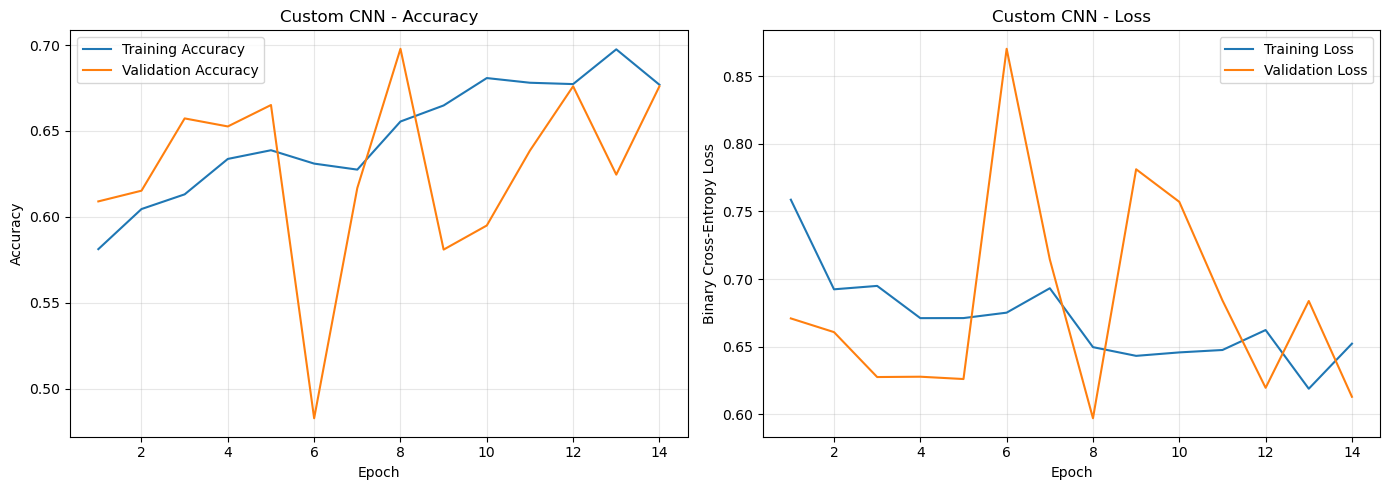

Best training accuracy: 69.75%
Best validation accuracy: 69.78%
Best validation epoch: 8


In [21]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history.history["accuracy"],
             label="Training Accuracy")
axes[0].plot(epochs_range, history.history["val_accuracy"],
             label="Validation Accuracy")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history.history["loss"],
             label="Training Loss")
axes[1].plot(epochs_range, history.history["val_loss"],
             label="Validation Loss")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "training_graphs.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Best training accuracy: {max(history.history['accuracy']) * 100:.2f}%")
print(f"Best validation accuracy: {max(history.history['val_accuracy']) * 100:.2f}%")
print("Best validation epoch:",
      np.argmin(history.history["val_loss"]) + 1)

In [22]:
val_results = model.evaluate(val_ds, verbose=1)

for name, value in zip(model.metrics_names, val_results):
    print(f"{name}: {value:.4f}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 128ms/step - accuracy: 0.6978 - loss: 0.5971 - precision: 0.7221 - recall: 0.8149
loss: 0.5971
compile_metrics: 0.6978


In [23]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in val_ds
]).astype(int)

y_prob = model.predict(val_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0) * 100:.2f}%")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0) * 100:.2f}%")
print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0) * 100:.2f}%")

2026-10-23 11:18:34.910984: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 141ms/step 
Accuracy:  56.70%
Precision: 62.64%
Recall:    70.69%
F1-score:  66.43%


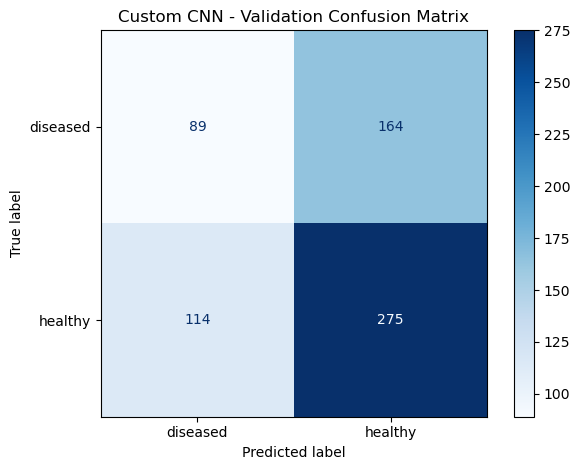

              precision    recall  f1-score   support

    diseased       0.44      0.35      0.39       253
     healthy       0.63      0.71      0.66       389

    accuracy                           0.57       642
   macro avg       0.53      0.53      0.53       642
weighted avg       0.55      0.57      0.56       642



In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Custom CNN - Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))